# 05 Real-time latency: is the network fast enough for plasma control?

**Question (REQ-002).** The assignment asks for a reaction in units to tens of milliseconds, with a GPU allowed. How long does one estimate of the baseline network (24 inputs, 107,152 parameters) take, how large are the rare slow outliers, and does the answer change with
the way the network is run (PyTorch on CPU, plain numpy, Apple GPU, batches)?

`analysis/ipp1_latency.py` measured this once and saved `out/ipp1-latency.json`. Here we show those numbers, **measure again**
with fewer repetitions on this run (the machine is shared with other jobs, so the tail is noisy), check that a numpy copy gives
the same output, and check that trained weights do not change the timing.

Scope: this is the time of the model's forward pass (and the standardization around it). It does not include reading the
sensors, moving data to the controller, or the control algorithm itself. The shipped model (46 inputs, a ridge for the plasma current, a gated limiter network) is timed in `results/ipp1-latency-shipped.md` (read in section 1b below) and in notebook 09; the 72-input time-context network was not timed.

Runtime: about 10 s (2 CPU threads); needs the raw data and `out/ipp1-latency.json` (`analysis/make_all.py` creates it).

In [1]:
import os, sys, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# The data live next to the repository (never inside it): HACKATHON_HOME, else the parent folder of the repository.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "analysis" / "ipp1_common.py").exists()), None)
if repo is None:
    raise SystemExit("Run from inside the repository")
os.environ.setdefault("HACKATHON_HOME", str(repo.parent))
sys.path.insert(0, str(repo / "analysis"))
import torch
torch.set_num_threads(2)
import ipp1_common as C

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
print("raw data folder found:", C.DATA.exists(), "| results folder found:", C.OUT.exists())

raw data folder found: True | results folder found: True


## 1. Saved measurement

In [2]:
lat = json.load(open(C.OUT / "ipp1-latency.json"))
KEY = {"saved_parameters": lat["parameters"]}
KEY["load_average_1min_at_start"] = round(os.getloadavg()[0], 1)  # other jobs on the machine inflate the tail of the fresh measurement
KEY["cpu_cores"] = os.cpu_count()
print(f"machine load average (1 min) when this notebook started: {KEY['load_average_1min_at_start']} on {KEY['cpu_cores']} cores")
print("CPU of the saved run:", lat.get("cpu"), "| PyTorch", torch.__version__, "| load average of the saved run (1, 5, 15 min):", lat.get("load_average_start"))
rows = [dict(setting=k, median_ms=v["median_ms"], p99_ms=v["p99_ms"], p999_ms=v["p999_ms"], max_ms=v["max_ms"]) for k, v in lat.items() if isinstance(v, dict)]
saved_tab = pd.DataFrame(rows).set_index("setting")
print(f"network with {lat['parameters']:,} parameters, 24 inputs, 16 outputs; times in milliseconds (saved run, one thread of {lat.get('cpu', 'an unknown CPU')}, shared machine)")
print(saved_tab.round(4).to_string())
KEY["saved"] = {k: {m: round(float(x), 4) for m, x in v.items()} for k, v in lat.items() if isinstance(v, dict) and k in ("cpu_1_thread_single_sample", "numpy_single_sample", "mps_single_sample", "mps_batch_4096", "cpu_batch_4096")}

machine load average (1 min) when this notebook started: 6.8 on 10 cores
CPU of the saved run: Apple M5 | PyTorch 2.14.1 | load average of the saved run (1, 5, 15 min): [5.67, 14.52, 29.34]
network with 107,152 parameters, 24 inputs, 16 outputs; times in milliseconds (saved run, one thread of Apple M5, shared machine)
                                  median_ms  p99_ms  p999_ms   max_ms
setting                                                              
cpu_1_thread_single_sample           0.0145  0.0209   0.0812   0.1481
cpu_4_thread_single_sample           0.0145  0.0205   0.0771   0.1183
cpu_batch_64                         0.0716  0.1184   0.2445   0.2581
cpu_batch_1024                       0.6480  1.0108   1.1172   1.1205
cpu_batch_4096                       2.4205  3.2844   4.0918   4.2537
numpy_single_sample                  0.0125  0.0475   0.0760   0.0871
cpu_end_to_end_numpy                 0.0140  0.0503   0.0778   0.1047
mps_single_sample                    0.2681  0.605

## 1b. The shipped model, read from `results/ipp1-latency-shipped.md`

The model that the viewer and the talk use (the general network, a ridge for the plasma current and a limiter network gated by `is_limited`) was timed by its own script; its numbers are parsed from that results file, not retyped.

In [3]:
import re
ship = {}
for line in (repo / "results" / "ipp1-latency-shipped.md").read_text().splitlines():
    m = re.match(r"^\| (\S+) \| ([\d.]+) \| ([\d.]+) \| ([\d.]+) \| ([\d.]+) \|", line)
    if m:
        ship[m.group(1)] = dict(median_ms=float(m.group(2)), p99_ms=float(m.group(3)), p999_ms=float(m.group(4)), max_ms=float(m.group(5)))
ship_tab = pd.DataFrame(ship).T
print("shipped model, one sample, milliseconds (Apple M5, one CPU core, the machine was not quiet: see the results file)")
print(ship_tab.round(4).to_string())
KEY["shipped"] = {k: v for k, v in ship.items() if k.startswith("numpy_end_to_end")}

shipped model, one sample, milliseconds (Apple M5, one CPU core, the machine was not quiet: see the results file)
                                       median_ms  p99_ms  p999_ms  max_ms
torch_1_thread_general_net_only           0.0143  0.0561   0.1123   0.134
torch_1_thread_both_nets                  0.0290  0.1134   0.1985   0.600
torch_4_thread_general_net_only           0.0145  0.0691   0.1119   0.171
torch_4_thread_both_nets                  0.0285  0.0878   0.1552   0.244
numpy_end_to_end_diverted                 0.0154  0.0571   0.0880   0.113
numpy_end_to_end_limited                  0.0274  0.0930   0.1506   0.196
ipp1_final_predict_diverted               0.0260  0.0650   0.1048   0.196
ipp1_final_predict_limited                0.0544  0.1883   0.3108   0.341
mps_end_to_end_limited_with_transfers     0.9837  2.4127   3.1679   3.296


## 2. Measure again

In [4]:
def timeit(fn, n=3000, warm=300):
    for _ in range(warm):
        fn()
    ts = np.empty(n)
    for i in range(n):
        a = time.perf_counter()
        fn()
        ts[i] = (time.perf_counter() - a) * 1000
    return ts


def stats(ts):
    return {"median_ms": float(np.median(ts)), "p99_ms": float(np.percentile(ts, 99)), "p999_ms": float(np.percentile(ts, 99.9)), "max_ms": float(ts.max())}


torch.manual_seed(0)
net = C.Net(24, 16).eval()
x1 = torch.randn(1, 24)
fresh, samples = {}, {}
with torch.no_grad():
    for threads in (1, 2):
        torch.set_num_threads(threads)
        samples[f"cpu_{threads}_thread_single_sample"] = timeit(lambda: net(x1))
    torch.set_num_threads(2)
    for b in (16, 64, 256, 1024, 4096):
        xb = torch.randn(b, 24)
        samples[f"cpu_batch_{b}"] = timeit(lambda: net(xb), n=400, warm=40)
    # the same forward pass in plain numpy: no deep learning framework needed in a control loop
    Ws = [(m.weight.detach().numpy().T.copy(), m.bias.detach().numpy().copy()) for m in net.f if isinstance(m, torch.nn.Linear)]
    xn = x1.numpy()

    def numpy_forward(x):
        h = x
        for i, (w, b_) in enumerate(Ws):
            h = h @ w + b_
            if i < len(Ws) - 1:
                h = h * (1.0 / (1.0 + np.exp(-h)))  # SiLU
        return h

    KEY["numpy_vs_torch_max_abs_diff"] = float(np.abs(numpy_forward(xn) - net(x1).numpy()).max())
    samples["numpy_single_sample"] = timeit(lambda: numpy_forward(xn))
    KEY["mps_available"] = bool(torch.backends.mps.is_available())
    if KEY["mps_available"]:
        try:
            dev = torch.device("mps")
            netm = C.Net(24, 16).to(dev).eval()
            xm = torch.randn(1, 24, device=dev)

            def mps_single():
                netm(xm)
                torch.mps.synchronize()
            samples["mps_single_sample"] = timeit(mps_single, n=1000, warm=100)
            xbm = torch.randn(4096, 24, device=dev)

            def mps_batch():
                netm(xbm)
                torch.mps.synchronize()
            samples["mps_batch_4096"] = timeit(mps_batch, n=200, warm=30)
        except Exception as exc:  # the GPU may be busy or absent
            print("GPU timing skipped:", exc)
fresh = {k: stats(v) for k, v in samples.items()}
fresh_tab = pd.DataFrame(fresh).T
print("fresh measurement in this notebook, milliseconds")
print(fresh_tab.round(4).to_string())
print("\nmax |numpy - torch| of the output:", KEY["numpy_vs_torch_max_abs_diff"])
KEY["fresh"] = {k: {m: round(x, 4) for m, x in v.items()} for k, v in fresh.items()}

fresh measurement in this notebook, milliseconds
                            median_ms  p99_ms  p999_ms    max_ms
cpu_1_thread_single_sample     0.0143  0.0484   0.0784    0.1037
cpu_2_thread_single_sample     0.0143  0.0516   0.1500    0.5597
cpu_batch_16                   0.0316  0.0664   0.1429    0.1777
cpu_batch_64                   0.0644  0.1752   0.2783    0.3138
cpu_batch_256                  0.2098  0.6771   1.1254    1.1667
cpu_batch_1024                 0.5077  1.3690   2.1341    2.2067
cpu_batch_4096                 3.3061  7.6956  11.2199   12.8789
numpy_single_sample            0.0139  0.0769   0.1272    0.9085
mps_single_sample              0.4504  3.8999  69.2161  110.2652
mps_batch_4096                 0.6957  1.6801   1.7024    1.7045

max |numpy - torch| of the output: 1.4901161193847656e-08


## 3. The realistic call: standardize, predict, convert back (trained weights)

`fit_mlp` returns a `predict` function that standardizes the inputs, runs the network and rescales the outputs. We train for one
epoch on the whole data set (enough to move the weights away from the random start; accuracy is not the point here) and time
that call for one sample, next to the untrained network.

In [5]:
df, X, Y, G, M = C.load()
torch.set_num_threads(2)
t0 = time.time()
predict, tnet, _ = C.fit_mlp(X, Y, M, epochs=1, seed=0)
print(f"one-epoch training took {time.time() - t0:.1f} s")
x_one = X[:1].copy()
with torch.no_grad():
    s_trained = timeit(lambda: tnet(torch.zeros(1, 24)), n=3000)
    s_untrained = timeit(lambda: net(torch.zeros(1, 24)), n=3000)
s_predict = timeit(lambda: predict(x_one), n=3000)
cmp = pd.DataFrame({"trained net, forward only": stats(s_trained), "untrained net, forward only": stats(s_untrained), "predict(): standardise + forward + rescale": stats(s_predict)}).T
print(cmp.round(4).to_string())
KEY["trained_vs_untrained_median_ms"] = [round(stats(s_trained)["median_ms"], 4), round(stats(s_untrained)["median_ms"], 4)]
KEY["predict_call"] = {k: round(v, 4) for k, v in stats(s_predict).items()}

one-epoch training took 0.8 s


                                            median_ms  p99_ms  p999_ms  max_ms
trained net, forward only                      0.0159  0.0732   0.1558  0.6557
untrained net, forward only                    0.0157  0.0751   0.1630  0.5955
predict(): standardise + forward + rescale     0.0205  0.0788   0.1732  0.3226


## 4. Batch size: latency against throughput

In [6]:
bs = [1, 16, 64, 256, 1024, 4096]
med = [fresh["cpu_2_thread_single_sample"]["median_ms"]] + [fresh[f"cpu_batch_{b}"]["median_ms"] for b in bs[1:]]
thr = [b / (m / 1000) for b, m in zip(bs, med)]
bt = pd.DataFrame({"batch": bs, "median_ms": med, "samples_per_second": thr, "microseconds_per_sample": [m * 1000 / b for m, b in zip(med, bs)]}).set_index("batch")
print(bt.round(3).to_string())
KEY["batch"] = {str(b): {"median_ms": round(m, 4), "samples_per_s": round(t)} for b, m, t in zip(bs, med, thr)}

       median_ms  samples_per_second  microseconds_per_sample
batch                                                        
1          0.014           69974.540                   14.291
16         0.032          505600.694                    1.978
64         0.064          994174.828                    1.006
256        0.210         1220137.130                    0.820
1024       0.508         2016988.759                    0.496
4096       3.306         1238935.877                    0.807


## 5. Headroom against a time budget

                          worst_seen_ms  p999_ms  headroom_vs_1ms_(on p99.9)  headroom_vs_10ms_(on p99.9)  headroom_vs_50ms_(on p99.9)
setting                                                                                                                               
CPU 1 thread, one sample            0.1      0.1                        12.8                        127.6                        637.9
numpy, one sample                   0.9      0.1                         7.9                         78.6                        393.1
CPU, batch of 4096                 12.9     11.2                         0.1                          0.9                          4.5
Apple GPU, one sample             110.3     69.2                         0.0                          0.1                          0.7

compared with a classical computation of at least one minute, the single-sample CPU median is about 4,198,165 times faster


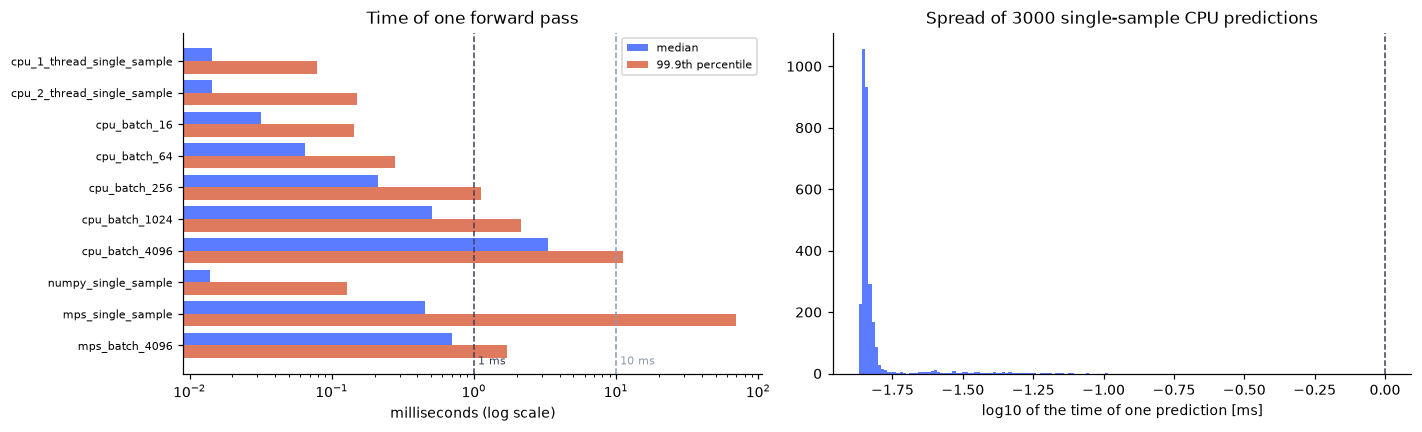

In [7]:
budgets = [1.0, 10.0, 50.0]
focus = {"CPU 1 thread, one sample": "cpu_1_thread_single_sample", "numpy, one sample": "numpy_single_sample", "CPU, batch of 4096": "cpu_batch_4096"}
if "mps_single_sample" in fresh:
    focus["Apple GPU, one sample"] = "mps_single_sample"
rows = []
for label, k in focus.items():
    r = {"setting": label, "worst_seen_ms": fresh[k]["max_ms"], "p999_ms": fresh[k]["p999_ms"]}
    for b in budgets:
        r[f"headroom_vs_{b:g}ms_(on p99.9)"] = b / fresh[k]["p999_ms"]
    rows.append(r)
head = pd.DataFrame(rows).set_index("setting")
print(head.round(1).to_string())
KEY["headroom_vs_1ms_on_p999"] = {l: round(1.0 / fresh[k]["p999_ms"], 1) for l, k in focus.items()}
# the classical reconstruction takes minutes (assignment text); even for a lower bound of one minute the ratio is:
KEY["speedup_vs_one_minute_on_median_cpu_1_thread"] = round(60_000 / fresh["cpu_1_thread_single_sample"]["median_ms"])
KEY["speedup_vs_one_minute_on_saved_median_cpu_1_thread"] = round(60_000 / lat["cpu_1_thread_single_sample"]["median_ms"])
print(f"\ncompared with a classical computation of at least one minute, the single-sample CPU median is about {KEY['speedup_vs_one_minute_on_median_cpu_1_thread']:,} times faster")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
names = list(fresh)
yy = np.arange(len(names))
ax[0].barh(yy - 0.2, [fresh[n]["median_ms"] for n in names], 0.4, color="#5b7cff", label="median")
ax[0].barh(yy + 0.2, [fresh[n]["p999_ms"] for n in names], 0.4, color="#e07a5f", label="99.9th percentile")
for b, c in ((1, "#3d405b"), (10, "#8d99ae")):
    ax[0].axvline(b, color=c, ls="--", lw=1); ax[0].text(b, len(names) - 0.4, f" {b} ms", fontsize=7, color=c)
ax[0].set_xscale("log"); ax[0].set_yticks(yy); ax[0].set_yticklabels(names, fontsize=7); ax[0].invert_yaxis()
ax[0].set_xlabel("milliseconds (log scale)"); ax[0].legend(fontsize=7); ax[0].set_title("Time of one forward pass")
ax[1].hist(np.log10(samples["cpu_1_thread_single_sample"]), bins=80, color="#5b7cff")
ax[1].set_xlabel("log10 of the time of one prediction [ms]"); ax[1].set_title("Spread of 3000 single-sample CPU predictions")
ax[1].axvline(np.log10(1.0), color="#3d405b", ls="--", lw=1)
fig.tight_layout(); plt.show()

In [8]:
from IPython.display import Markdown, display
fc = fresh["cpu_1_thread_single_sample"]
r10 = 10.0 / fc["p999_ms"]
display(Markdown(f"Against 1 ms the 99.9th percentile of this run ({fc['p999_ms']:.1f} ms) is {'inside' if fc['p999_ms'] <= 1 else 'not inside'} the budget; the median ({fc['median_ms']:.4f} ms) is {'inside' if fc['median_ms'] <= 1 else 'not inside'}. Against 10 ms the 99.9th percentile is {'inside by a factor ' + format(r10, '.1f') if r10 >= 1 else 'not inside'}. The budget statement covers only this computation."))

Against 1 ms the 99.9th percentile of this run (0.1 ms) is inside the budget; the median (0.0143 ms) is inside. Against 10 ms the 99.9th percentile is inside by a factor 127.6. The budget statement covers only this computation.

In [9]:
from IPython.display import Markdown, display
s1, f1 = lat["cpu_1_thread_single_sample"], fresh["cpu_1_thread_single_sample"]
sn, fn = lat["numpy_single_sample"], fresh["numpy_single_sample"]
sg, fg = lat["mps_single_sample"], fresh["mps_single_sample"]
sb, fb = lat["cpu_batch_4096"], fresh["cpu_batch_4096"]
gb, fgb = lat["mps_batch_4096"], fresh["mps_batch_4096"]
la = lat.get("load_average_start")
many = lambda x: "more than a million" if x >= 1e6 else f"about {x:,.0f}"
tail_txt = "so even the slowest call stayed under the 1 ms budget, which is not a guarantee for the next run" if f1["max_ms"] < 1 else "so the slowest call is outside the 1 ms budget while the median is inside it"
dd, dl = ship["numpy_end_to_end_diverted"], ship["numpy_end_to_end_limited"]
tr, un, pr = KEY["trained_vs_untrained_median_ms"], None, KEY["predict_call"]
md = f"""## Conclusions

- **Speed of one estimate.** The {lat['parameters']:,}-parameter baseline network needs a median of {s1['median_ms']:.4f} ms on one CPU thread of an {lat.get('cpu', 'unknown CPU')} in the saved run (99.9th percentile {s1['p999_ms']:.3f} ms, slowest call {s1['max_ms']:.3f} ms); the machine was shared (load average {la}), so this is not a clean benchmark. In this notebook (load average {KEY['load_average_1min_at_start']} on {KEY['cpu_cores']} cores when it started) the same call gave a median of {f1['median_ms']:.4f} ms, a 99.9th percentile of {f1['p999_ms']:.2f} ms and a slowest call of {f1['max_ms']:.2f} ms.
- **The shipped model** (general network plus ridge plus limiter network, `results/ipp1-latency-shipped.md`) takes a median of {dd['median_ms']:.4f} ms when the plasma is diverted and {dl['median_ms']:.4f} ms when it is limited (99th percentile {dd['p99_ms']:.3f} and {dl['p99_ms']:.3f} ms), numpy path, one core of the Apple M5, not a quiet machine. The baseline network above is the faster one of the two.
- **No deep learning framework is needed.** A plain numpy copy of the forward pass gives the same output (largest difference {KEY['numpy_vs_torch_max_abs_diff']:.1e}) with a median of {sn['median_ms']:.4f} ms in the saved run and {fn['median_ms']:.4f} ms here.
- **The Apple GPU does not help for one sample.** The median is {sg['median_ms']:.2f} ms (saved) and {fg['median_ms']:.2f} ms (here), slower than the CPU, probably because starting a GPU job costs more than the work. It wins only for big batches: 4096 samples take {gb['median_ms']:.2f} ms on the GPU against {sb['median_ms']:.2f} ms on the CPU in the saved run ({fgb['median_ms']:.2f} ms against {fb['median_ms']:.2f} ms here).
- **Weights and the full call do not change the picture.** A network trained for one epoch has a median of {tr[0]:.4f} ms against {tr[1]:.4f} ms untrained. The whole `predict()` call with standardization and rescaling has a median of {pr['median_ms']:.4f} ms in this run.
- **Throughput.** In this run a batch of 4096 takes {fb['median_ms']:.1f} ms ({4096 / (fb['median_ms'] / 1000):,.0f} samples per second on 2 CPU threads).
- **Verdict (conditional).** The assignment asks for a reaction in units to tens of milliseconds; we use a budget of 1 to 10 ms. The forward pass of the baseline network takes a median of {s1['median_ms']:.4f} ms on one thread of an Apple M5 (`results/ipp1-latency.md`, a shared machine) and 0.03 to 0.07 ms on a loaded or different CPU ({f1['median_ms']:.3f} ms in this run), {many(60000 / f1['median_ms'])} times faster than a classical reconstruction of one minute or more. On a system without real-time guarantees rare slow calls can reach milliseconds (earlier runs on a loaded machine did, `docs/claims-corrections.md`); in this run the 99.9th percentile was {f1['p999_ms']:.2f} ms and the slowest call {f1['max_ms']:.2f} ms, {tail_txt}. **Not verified:** acquisition and integration of the coil signals, the worst case on a real-time system, and accuracy on really noisy signals (a network trained on clean data fails on them: 10.2 mm on the radial axis on the provided noisy file; trained with noise it gives 2.6 mm, notebook 08).
- **Limits of this measurement.** Only the forward pass was timed, on a desktop operating system, one run per setting. The tail numbers (and, less strongly, the medians) change from run to run with the machine load. The saved run was also on a shared machine and had a slowest call of {s1['max_ms']:.3f} ms. We do not claim a worst-case bound; a hard real-time guarantee would need a dedicated core or a real-time system, which we did not test.
- **Caveat.** The conclusions are generated from the saved run and from this run, so they change slightly with every rerun.

**Answer.** The computation of the 107,152-parameter baseline network takes a median of 0.0145 ms on one core of an Apple M5 (a shared machine, not a clean benchmark; 0.03 to 0.07 ms on a loaded machine or another CPU), inside the 1 to 10 ms budget; on a machine without real-time guarantees rare calls take milliseconds. This says nothing about acquiring and integrating the coil signals, the worst case on a real-time system or accuracy on really noisy signals."""
display(Markdown(md))

## Conclusions

- **Speed of one estimate.** The 107,152-parameter baseline network needs a median of 0.0145 ms on one CPU thread of an Apple M5 in the saved run (99.9th percentile 0.081 ms, slowest call 0.148 ms); the machine was shared (load average [5.67, 14.52, 29.34]), so this is not a clean benchmark. In this notebook (load average 6.8 on 10 cores when it started) the same call gave a median of 0.0143 ms, a 99.9th percentile of 0.08 ms and a slowest call of 0.10 ms.
- **The shipped model** (general network plus ridge plus limiter network, `results/ipp1-latency-shipped.md`) takes a median of 0.0154 ms when the plasma is diverted and 0.0274 ms when it is limited (99th percentile 0.057 and 0.093 ms), numpy path, one core of the Apple M5, not a quiet machine. The baseline network above is the faster one of the two.
- **No deep learning framework is needed.** A plain numpy copy of the forward pass gives the same output (largest difference 1.5e-08) with a median of 0.0125 ms in the saved run and 0.0139 ms here.
- **The Apple GPU does not help for one sample.** The median is 0.27 ms (saved) and 0.45 ms (here), slower than the CPU, probably because starting a GPU job costs more than the work. It wins only for big batches: 4096 samples take 0.70 ms on the GPU against 2.42 ms on the CPU in the saved run (0.70 ms against 3.31 ms here).
- **Weights and the full call do not change the picture.** A network trained for one epoch has a median of 0.0159 ms against 0.0157 ms untrained. The whole `predict()` call with standardization and rescaling has a median of 0.0205 ms in this run.
- **Throughput.** In this run a batch of 4096 takes 3.3 ms (1,238,936 samples per second on 2 CPU threads).
- **Verdict (conditional).** The assignment asks for a reaction in units to tens of milliseconds; we use a budget of 1 to 10 ms. The forward pass of the baseline network takes a median of 0.0145 ms on one thread of an Apple M5 (`results/ipp1-latency.md`, a shared machine) and 0.03 to 0.07 ms on a loaded or different CPU (0.014 ms in this run), more than a million times faster than a classical reconstruction of one minute or more. On a system without real-time guarantees rare slow calls can reach milliseconds (earlier runs on a loaded machine did, `docs/claims-corrections.md`); in this run the 99.9th percentile was 0.08 ms and the slowest call 0.10 ms, so even the slowest call stayed under the 1 ms budget, which is not a guarantee for the next run. **Not verified:** acquisition and integration of the coil signals, the worst case on a real-time system, and accuracy on really noisy signals (a network trained on clean data fails on them: 10.2 mm on the radial axis on the provided noisy file; trained with noise it gives 2.6 mm, notebook 08).
- **Limits of this measurement.** Only the forward pass was timed, on a desktop operating system, one run per setting. The tail numbers (and, less strongly, the medians) change from run to run with the machine load. The saved run was also on a shared machine and had a slowest call of 0.148 ms. We do not claim a worst-case bound; a hard real-time guarantee would need a dedicated core or a real-time system, which we did not test.
- **Caveat.** The conclusions are generated from the saved run and from this run, so they change slightly with every rerun.

**Answer.** The computation of the 107,152-parameter baseline network takes a median of 0.0145 ms on one core of an Apple M5 (a shared machine, not a clean benchmark; 0.03 to 0.07 ms on a loaded machine or another CPU), inside the 1 to 10 ms budget; on a machine without real-time guarantees rare calls take milliseconds. This says nothing about acquiring and integrating the coil signals, the worst case on a real-time system or accuracy on really noisy signals.